Démarrage de l'analyse des flux RSS français...
Utilisation des flux RSS de presse française sélectionnés...
Validation des flux de presse...
Test de Le Monde: https://www.lemonde.fr/rss/une.xml
✓ Le Monde validé
Test de Le Figaro: https://www.lefigaro.fr/rss/figaro_actualites.xml
✓ Le Figaro validé
Test de Libération: https://www.liberation.fr/arc/outboundfeeds/rss-all/
✓ Libération validé
Test de 20 Minutes: https://www.20minutes.fr/feeds/rss-actu.xml
✗ 20 Minutes non accessible
Test de L'Express: https://www.lexpress.fr/rss/alaune.xml
✓ L'Express validé
Test de Le Nouvel Observateur: https://www.nouvelobs.com/rss.xml
✓ Le Nouvel Observateur validé
Test de Marianne: https://www.marianne.net/rss.xml
✓ Marianne validé
Test de Les Échos: https://www.lesechos.fr/rss/monde.xml
✗ Les Échos non accessible
Test de Le Parisien: https://www.leparisien.fr/rss.php
✗ Le Parisien non accessible
Test de La Tribune: https://www.latribune.fr/rss/a-la-une.xml
✗ La Tribune non accessible
Test de L'Huma

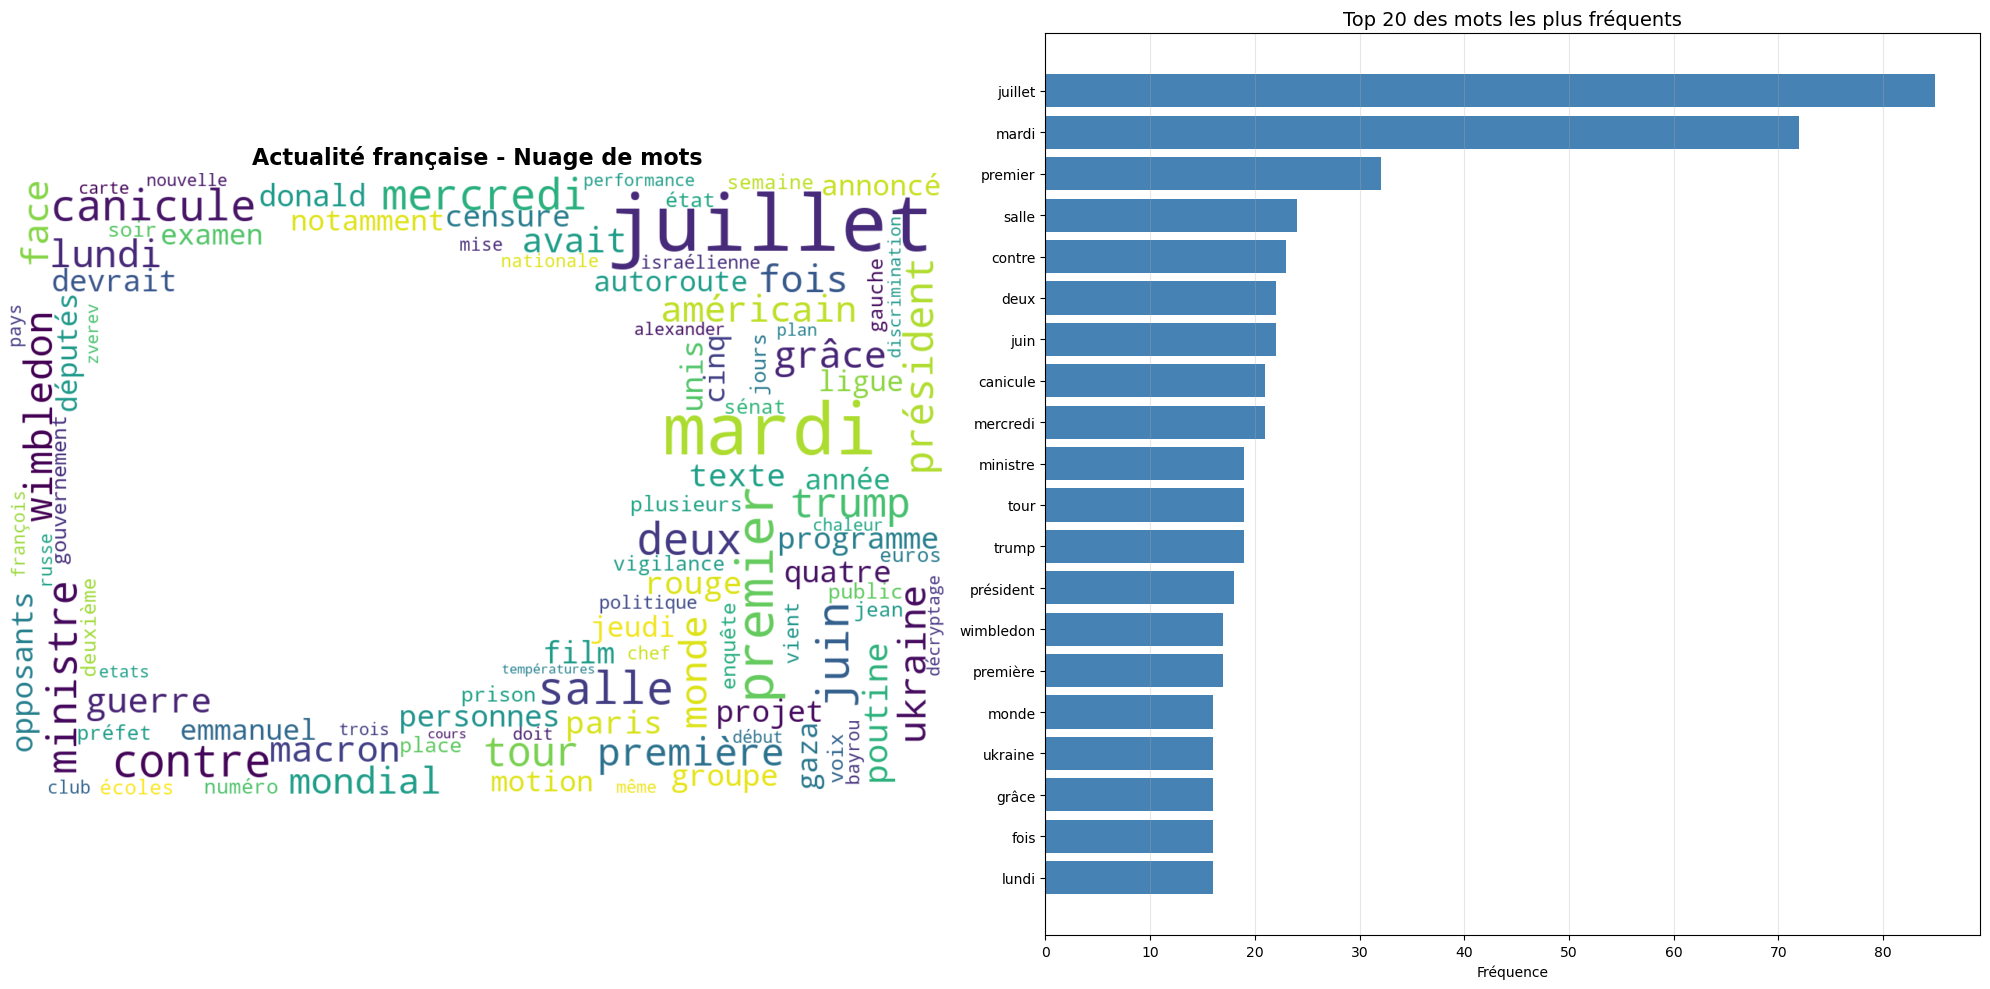


RAPPORT D'ANALYSE DE L'ACTUALITÉ FRANÇAISE
Nombre de flux RSS analysés: 8
Nombre d'articles récupérés: 159

Derniers titres:
1. Canicule dans les établissements scolaires : « J’ai concocté à ma fille un petit...
2. Incendie dans l’Aude : le suspect, qui transportait un barbecue mal éteint, mis ...
3. Andreï Klepach, économiste russe : « La défense et la sécurité nationale sont au...
4. En direct, guerre en Ukraine : Vladimir Poutine déclare à Emmanuel Macron que le...
5. Assemblée nationale : François Bayrou s’offre un nouveau sursis grâce au Rassemb...

Flux RSS utilisés:
1. https://www.lemonde.fr/rss/une.xml
2. https://www.lefigaro.fr/rss/figaro_actualites.xml
3. https://www.liberation.fr/arc/outboundfeeds/rss-all/
4. https://www.lexpress.fr/rss/alaune.xml
5. https://www.nouvelobs.com/rss.xml
6. https://www.marianne.net/rss.xml
7. https://www.ouest-france.fr/rss-en-continu.xml
8. https://www.sudouest.fr/rss.xml

Analyse terminée !
Le nuage de mots a été généré et sauvegardé.

Top 10

In [5]:
# Analyseur de flux RSS français avec nuage de mots sur carte de France
# Notebook pour analyser l'actualité française et créer une visualisation

import requests
from bs4 import BeautifulSoup
import feedparser
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import re
from collections import Counter
from urllib.parse import urljoin, urlparse
import time
import warnings
warnings.filterwarnings('ignore')

# Configuration
plt.rcParams['figure.figsize'] = (15, 10)
plt.style.use('default')

class RSSAnalyzer:
    def __init__(self):
        self.rss_feeds = []
        self.articles = []
        self.stop_words = self._get_french_stop_words()
        
    def _get_french_stop_words(self):
        """Définit les mots vides français à exclure"""
        return {
            'le', 'de', 'et', 'à', 'un', 'il', 'être', 'et', 'en', 'avoir', 'que', 'pour',
            'dans', 'ce', 'son', 'une', 'sur', 'avec', 'ne', 'se', 'pas', 'tout', 'plus',
            'par', 'grand', 'en', 'le', 'la', 'les', 'des', 'du', 'au', 'aux', 'ce', 'cette',
            'ces', 'cet', 'un', 'une', 'uns', 'unes', 'de', 'du', 'des', 'dans', 'pour',
            'sur', 'avec', 'sans', 'sous', 'entre', 'vers', 'chez', 'pendant', 'avant',
            'après', 'depuis', 'jusqu', 'jusque', 'lors', 'alors', 'ainsi', 'aussi',
            'mais', 'ou', 'où', 'donc', 'or', 'ni', 'car', 'si', 'comme', 'quand',
            'lorsque', 'puisque', 'bien', 'que', 'qui', 'quoi', 'dont', 'où', 'comment',
            'pourquoi', 'combien', 'très', 'trop', 'plus', 'moins', 'beaucoup', 'peu',
            'assez', 'encore', 'déjà', 'toujours', 'jamais', 'souvent', 'parfois',
            'hier', 'aujourd', 'hui', 'demain', 'maintenant', 'ici', 'là', 'ailleurs',
            'partout', 'quelque', 'part', 'nulle', 'part', 'je', 'tu', 'il', 'elle',
            'nous', 'vous', 'ils', 'elles', 'me', 'te', 'se', 'nous', 'vous', 'leur',
            'leurs', 'mon', 'ton', 'son', 'ma', 'ta', 'sa', 'mes', 'tes', 'ses',
            'notre', 'votre', 'nos', 'vos', 'avoir', 'être', 'faire', 'dire', 'aller',
            'voir', 'savoir', 'pouvoir', 'falloir', 'vouloir', 'venir', 'prendre',
            'donner', 'mettre', 'porter', 'tenir', 'rendre', 'partir', 'sortir',
            'va', 'vont', 'est', 'sont', 'était', 'étaient', 'sera', 'seront',
            'été', 'fait', 'faite', 'faits', 'faites', 'dit', 'dite', 'dits', 'dites',
            'france', 'français', 'française', 'françaises', 'selon', 'afp'
        }
    
    def extract_rss_feeds(self, url=None):
        """Utilise uniquement les flux RSS de presse française sélectionnés"""
        print("Utilisation des flux RSS de presse française sélectionnés...")
        
        # Flux RSS de presse française spécifiquement sélectionnés
        press_feeds = {
            # Presse nationale
            'Le Monde': 'https://www.lemonde.fr/rss/une.xml',
            'Le Figaro': 'https://www.lefigaro.fr/rss/figaro_actualites.xml',
            'Libération': 'https://www.liberation.fr/arc/outboundfeeds/rss-all/',
            '20 Minutes': 'https://www.20minutes.fr/feeds/rss-actu.xml',
            'L\'Express': 'https://www.lexpress.fr/rss/alaune.xml',
            'Le Nouvel Observateur': 'https://www.nouvelobs.com/rss.xml',
            'Marianne': 'https://www.marianne.net/rss.xml',
            'Les Échos': 'https://www.lesechos.fr/rss/monde.xml',
            'Le Parisien': 'https://www.leparisien.fr/rss.php',
            'La Tribune': 'https://www.latribune.fr/rss/a-la-une.xml',
            'L\'Humanité': 'https://www.humanite.fr/rss.xml',
            'La Croix': 'https://www.croix.com/RSS/RSS-Une',
            'Courrier International': 'https://www.courrierinternational.com/rss/actualites.xml',
            # Presse régionale
            'Ouest-France': 'https://www.ouest-france.fr/rss-en-continu.xml',
            'Sud Ouest': 'https://www.sudouest.fr/rss.xml',
            'La Provence': 'https://www.laprovence.com/rss/une.xml'
        }
        
        # Valider chaque flux
        valid_feeds = []
        print("Validation des flux de presse...")
        
        for press_name, feed_url in press_feeds.items():
            print(f"Test de {press_name}: {feed_url}")
            if self._validate_rss_feed(feed_url):
                valid_feeds.append(feed_url)
                print(f"✓ {press_name} validé")
            else:
                print(f"✗ {press_name} non accessible")
        
        self.rss_feeds = valid_feeds
        print(f"\nValidé {len(valid_feeds)} flux de presse sur {len(press_feeds)} testés")
        
        # Afficher la liste des flux validés
        if valid_feeds:
            print("\nFlux de presse utilisés:")
            for i, feed in enumerate(valid_feeds, 1):
                # Trouver le nom du journal
                journal = next((name for name, url in press_feeds.items() if url == feed), feed)
                print(f"{i:2d}. {journal}")
        
        return valid_feeds
    
    def _validate_rss_feed(self, feed_url):
        """Valide qu'un URL est bien un flux RSS valide"""
        try:
            headers = {
                'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36'
            }
            response = requests.get(feed_url, timeout=10, headers=headers, allow_redirects=True)
            if response.status_code == 200:
                # Vérifier que c'est du XML avec des éléments RSS
                content = response.text.lower()
                is_rss = any(tag in content for tag in ['<rss', '<feed', '<channel', '<item', '<entry'])
                if is_rss:
                    # Test avec feedparser pour s'assurer que c'est parsable
                    feed = feedparser.parse(response.content)
                    return len(feed.entries) > 0
        except Exception as e:
            print(f"Erreur validation {feed_url}: {e}")
        return False
    
    def fetch_articles(self, max_feeds=20, max_articles_per_feed=25):
        """Récupère les articles depuis les flux RSS"""
        print("Récupération des articles...")
        self.articles = []
        
        for i, feed_url in enumerate(self.rss_feeds[:max_feeds]):
            try:
                print(f"Traitement du flux {i+1}/{min(len(self.rss_feeds), max_feeds)}: {feed_url[:50]}...")
                
                headers = {
                    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'
                }
                
                # Utiliser requests puis feedparser pour plus de robustesse
                response = requests.get(feed_url, timeout=15, headers=headers)
                if response.status_code == 200:
                    feed = feedparser.parse(response.content)
                else:
                    # Fallback: essayer directement avec feedparser
                    feed = feedparser.parse(feed_url)
                
                if feed.entries:
                    print(f"  → {len(feed.entries)} articles trouvés")
                    for entry in feed.entries[:max_articles_per_feed]:
                        article = {
                            'title': entry.get('title', ''),
                            'summary': entry.get('summary', ''),
                            'description': entry.get('description', ''),
                            'published': entry.get('published', ''),
                            'link': entry.get('link', ''),
                            'source': feed_url
                        }
                        
                        # Combiner titre et résumé pour l'analyse
                        full_text = f"{article['title']} {article['summary']} {article['description']}"
                        article['full_text'] = full_text
                        
                        self.articles.append(article)
                else:
                    print(f"  → Aucun article trouvé")
                
                time.sleep(1)  # Pause entre les requêtes
                
            except Exception as e:
                print(f"  → Erreur: {e}")
                continue
        
        print(f"Récupéré {len(self.articles)} articles au total")
        return len(self.articles)
    
    def extract_keywords(self, min_length=3, top_n=100):
        """Extrait les mots-clés les plus fréquents"""
        print("Extraction des mots-clés...")
        
        all_text = ' '.join([article['full_text'] for article in self.articles])
        
        # Nettoyage du texte
        text = re.sub(r'[^\w\s]', ' ', all_text.lower())
        text = re.sub(r'\d+', '', text)  # Supprimer les chiffres
        text = re.sub(r'\s+', ' ', text)  # Normaliser les espaces
        
        # Extraction des mots
        words = text.split()
        
        # Filtrage
        filtered_words = [
            word for word in words 
            if len(word) >= min_length 
            and word not in self.stop_words
            and not word.isdigit()
        ]
        
        # Comptage des fréquences
        word_freq = Counter(filtered_words)
        
        print(f"Analysé {len(filtered_words)} mots, trouvé {len(word_freq)} mots uniques")
        
        return dict(word_freq.most_common(top_n))
    
    def create_france_wordcloud(self, keywords, save_path='france_wordcloud.png'):
        """Crée un nuage de mots en forme de France"""
        print("Création du nuage de mots...")
        
        # Masque de la France (forme simplifiée)
        france_mask = self._create_france_mask()
        
        # Configuration du nuage de mots
        wordcloud = WordCloud(
            width=1200,
            height=800,
            background_color='white',
            mask=france_mask,
            max_words=100,
            colormap='viridis',
            relative_scaling=0.5,
            min_font_size=10,
            max_font_size=100,
            font_path=None,  # Utilise la police par défaut
            prefer_horizontal=0.7
        ).generate_from_frequencies(keywords)
        
        # Création du graphique
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))
        
        # Nuage de mots
        ax1.imshow(wordcloud, interpolation='bilinear')
        ax1.axis('off')
        ax1.set_title('Actualité française - Nuage de mots', fontsize=16, fontweight='bold')
        
        # Graphique des mots les plus fréquents
        top_words = list(keywords.keys())[:20]
        top_freqs = list(keywords.values())[:20]
        
        ax2.barh(range(len(top_words)), top_freqs, color='steelblue')
        ax2.set_yticks(range(len(top_words)))
        ax2.set_yticklabels(top_words)
        ax2.invert_yaxis()
        ax2.set_xlabel('Fréquence')
        ax2.set_title('Top 20 des mots les plus fréquents', fontsize=14)
        ax2.grid(axis='x', alpha=0.3)
        
        plt.tight_layout()
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()
        
        return fig
    
    def _create_france_mask(self):
        """Crée un masque approximatif de la forme de la France"""
        # Masque simplifié de la France (hexagone approximatif)
        mask = np.zeros((800, 1200))
        
        # Coordonnées approximatives pour dessiner la forme de la France
        from matplotlib.patches import Polygon
        import matplotlib.pyplot as plt
        
        # Points pour approximer la forme de la France
        france_points = np.array([
            [300, 100],   # Nord
            [500, 150],   # Nord-Est
            [650, 300],   # Est
            [600, 500],   # Sud-Est
            [400, 650],   # Sud
            [200, 600],   # Sud-Ouest
            [150, 400],   # Ouest
            [200, 200]    # Nord-Ouest
        ])
        
        # Créer le masque
        from PIL import Image, ImageDraw
        
        img = Image.new('L', (1200, 800), 0)
        draw = ImageDraw.Draw(img)
        
        # Dessiner un polygone approximatif de la France
        polygon_points = [
            (300, 100), (500, 80), (700, 150), (850, 250),
            (800, 400), (750, 550), (600, 650), (400, 700),
            (200, 650), (100, 500), (80, 350), (150, 200)
        ]
        
        draw.polygon(polygon_points, fill=255)
        
        return np.array(img)
    
    def generate_report(self):
        """Génère un rapport complet"""
        print("\n" + "="*50)
        print("RAPPORT D'ANALYSE DE L'ACTUALITÉ FRANÇAISE")
        print("="*50)
        print(f"Nombre de flux RSS analysés: {len(self.rss_feeds)}")
        print(f"Nombre d'articles récupérés: {len(self.articles)}")
        
        if self.articles:
            print(f"\nDerniers titres:")
            for i, article in enumerate(self.articles[:5]):
                print(f"{i+1}. {article['title'][:80]}...")
        
        print("\nFlux RSS utilisés:")
        for i, feed in enumerate(self.rss_feeds[:10]):
            print(f"{i+1}. {feed}")

# Fonction principale pour exécuter l'analyse
def run_analysis():
    """Exécute l'analyse complète"""
    analyzer = RSSAnalyzer()
    
    # 1. Utiliser directement les flux de presse sélectionnés
    feeds = analyzer.extract_rss_feeds()
    
    if not feeds:
        print("Aucun flux de presse accessible")
        return
    
    # 2. Récupérer les articles
    article_count = analyzer.fetch_articles(max_feeds=20, max_articles_per_feed=25)
    
    if article_count == 0:
        print("Aucun article récupéré")
        return
    
    # 3. Extraire les mots-clés
    keywords = analyzer.extract_keywords(min_length=4, top_n=150)
    
    # 4. Créer le nuage de mots
    if keywords:
        analyzer.create_france_wordcloud(keywords)
    
    # 5. Générer le rapport
    analyzer.generate_report()
    
    return analyzer, keywords

# Exécution
if __name__ == "__main__":
    print("Démarrage de l'analyse des flux RSS français...")
    analyzer, keywords = run_analysis()
    
    print("\nAnalyse terminée !")
    print("Le nuage de mots a été généré et sauvegardé.")
    
    # Afficher les mots les plus fréquents
    if keywords:
        print("\nTop 10 des mots les plus fréquents dans l'actualité:")
        for i, (word, freq) in enumerate(list(keywords.items())[:10], 1):
            print(f"{i:2d}. {word:<15} ({freq} occurrences)")